# COCO Captions
## Select and preprocess your image–caption dataset. Choose a dataset (COCO Captions, Flickr30k, Conceptual Captions, or a curated LAION subset) and curate a working subset of roughly 1k–5k image–caption pairs. Apply consistent image resizing, normalization, and a caption-cleaning pipeline (length filters, deduplication, quality heuristics, optional content filter). Document license, domain coverage, and ethical considerations in a short dataset memo.

In [7]:
# Import COCO Captions
# !pip install pycocotools
!pip install fiftyone

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
   ---------------------------------------- 0.0/24.0 MB ? eta -:--:--
   -------- ------------------------------- 5.2/24.0 MB 26.2 MB/s eta 0:00:01
   ----------------- ---------------------- 10.7/24.0 MB 26.1 MB/s eta 0:00:01
   -------------------------- ------------- 16.0/24.0 MB 26.0 MB/s eta 0:00:01
   ---------------------------------- ----- 20.7/24.0 MB 25.0 MB/s eta 0:00:01
   ---------------------------------------- 24.0/24.0 MB 23.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
   ------------------ --------------------- 7.3/16.1 MB 34.9 MB/s eta 0:00:01
   ---------------------------------- ----- 13.9/16.1 MB 33.7 MB/s eta 0:00:01
   ---------------------------------------- 16.1/16.1 MB 30.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/25.7 MB ? eta -:--:--
   -------- ------------------------------- 5.5/25.7 MB 26

  DEPRECATION: Building 'glob2' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'glob2'. Discussion can be found at https://github.com/pypa/pip/issues/6334
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiobotocore 2.19.0 requires botocore<1.36.4,>=1.36.0, but you have botocore 1.43.118 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
streamlit 1.45.1 requires pillow<12,>=7.1.0, but you have pillow 13.0.0 which is incompatible.



   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plotly]
   ----------- ---------------------------- 15/53 [plot

In [8]:
# Clean captions
import re

def clean_caption(text, min_words=3, max_words=40):
    text = re.sub(r"\s+", " ", text).strip()
    words = text.split()

    if not min_words <= len(words) <= max_words:
        return None

    # Optional: reject captions with no letters or digits
    if not re.search(r"[A-Za-z0-9]", text):
        return None

    return text

In [13]:
# Load in the COCO dataset using FiftyOne
import fiftyone as fo
import fiftyone.zoo as foz

dataset = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    label_types=["detections"],
    max_samples=3000,
    shuffle=True,
)

# print("Samples:", len(dataset))
# print("Fields:", dataset.get_field_schema())

Found annotations at 'C:\Users\Julia\fiftyone\coco-2017\raw\instances_train2017.json'
Sufficient images already downloaded
Existing download of split 'train' is sufficient
Loading 'coco-2017' split 'train'
 100% |███████████████| 3000/3000 [51.1s elapsed, 0s remaining, 56.2 samples/s]      
Dataset 'coco-2017-train-3000' created


In [35]:
import json
from collections import defaultdict
from PIL import Image
from torch.utils.data import Dataset

class COCODataset(Dataset):
    def __init__(self, fo_dataset, captions_json, transform=None):
        self.transform = transform
        captions_by_id = defaultdict(list)
        seen_by_id = defaultdict(set)

        with open(captions_json, "r", encoding="utf-8") as f:
            coco_data = json.load(f)

        for ann in coco_data["annotations"]:
            text = clean_caption(ann.get("caption", ""))
            if not text:
                continue

            image_id = int(ann["image_id"])
            key = text.casefold()
            if key not in seen_by_id[image_id]:
                seen_by_id[image_id].add(key)
                captions_by_id[image_id].append(text)

        self.samples = []
        
        # Map COCO image filenames to their captions
        captions_by_filename = {
            image_info["file_name"]: captions_by_id.get(image_info["id"], [])
            for image_info in coco_data["images"]
        }
        
        # Match FiftyOne images to captions by filename
        for sample in fo_dataset:
            filename = os.path.basename(sample.filepath)
            captions = captions_by_filename.get(filename, [])
        
            if captions:
                self.samples.append((sample.filepath, captions))
        
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, captions = self.samples[idx]

        with Image.open(path) as im:
            image = im.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, captions

In [22]:
from torchvision import transforms

# Resize and normalize the image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # these are based off of the ImageNet dataset: https://medium.com/@rohollah2afzali/why-do-we-normalize-images-aa51ec704d86
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [28]:
# import json
# import os

# captions_json = r"C:\Users\Julia\Development\IE7615-Group3-Project2\Milestone 1\dataset\captions_train2017.json"

# if not os.path.isfile(captions_json):
#     raise FileNotFoundError(
#         f"Captions file not found: {captions_json}"
#     )

# with open(captions_json, "r", encoding="utf-8") as f:
#     coco_data = json.load(f)


In [31]:
print(dataset.get_field_schema().keys())

sample = dataset.first()
print(sample)
print(sample.filepath)

odict_keys(['id', 'filepath', 'tags', 'metadata', 'created_at', 'last_modified_at', 'ground_truth'])
<Sample: {
    'id': '6adcbc5fe7f5fb9d82ce8d31',
    'media_type': 'image',
    'filepath': 'C:\\Users\\Julia\\fiftyone\\coco-2017\\train\\data\\000000549988.jpg',
    'tags': ['train'],
    'metadata': <ImageMetadata: {
        'size_bytes': None,
        'mime_type': None,
        'width': 640,
        'height': 480,
        'num_channels': None,
    }>,
    'created_at': datetime.datetime(2026, 10, 24, 14, 10, 39, 131000),
    'last_modified_at': datetime.datetime(2026, 10, 24, 14, 10, 39, 131000),
    'ground_truth': <Detections: {
        'detections': [
            <Detection: {
                'id': '6adcbc5ee7f5fb9d82ce8d2f',
                'attributes': {},
                'tags': [],
                'label': 'person',
                'bounding_box': [0.0016875000000000002, 0.88175, 0.753375, 0.108125],
                'mask': None,
                'mask_path': None,
         

In [36]:
# Implement the dataset 
captions_json = r"C:\Users\Julia\Development\IE7615-Group3-Project2\Milestone 1\dataset\captions_train2017.json"
coco_dataset = COCODataset(dataset, captions_json, transform)

In [43]:
# Verify the dataset is working
def collate_fn(batch):
    images, captions = zip(*batch)
    return torch.stack(images), list(captions)

coco_dataloader = DataLoader(
    coco_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn,
)

# coco_dataloader = DataLoader(coco_dataset, batch_size=4, shuffle=True)
for images, captions in coco_dataloader:
    print("Images shape:", images.shape)
    print("Captions:", captions)
    break

Images shape: torch.Size([4, 3, 224, 224])
Captions: [['there are many black cows that are on this field', 'A bunch of cows standing in a field grazing in the grass with mountain behind them.', 'A group of cows are standing in a field.', 'A group of cows scattered throughout a field.', 'A cattle in the wild is standing away from the pack.'], ['A small white bard with a long beak on a branch.', 'A small bird standing on some tree branches', 'The beak of the hummingbird enables it to suck nectar easily from many flower varieties.', 'a closeup of a small bird in trees', 'A bird perched on a branch in a forest.'], ['A row of meatball sandwiches sitting on a plate.', 'A plate topped with meat ball sandwiches smothered in sauce.', 'Nine sandwiches on rolls fills up a plate', 'A tray full of many sandwiches on a table.', 'Nine buns loaded with various food and condiments.'], ['A very tall clock tower towering over a small city.', 'A tall building with clocks on different areas of the building

Images shape: torch.Size([4, 3, 224, 224])


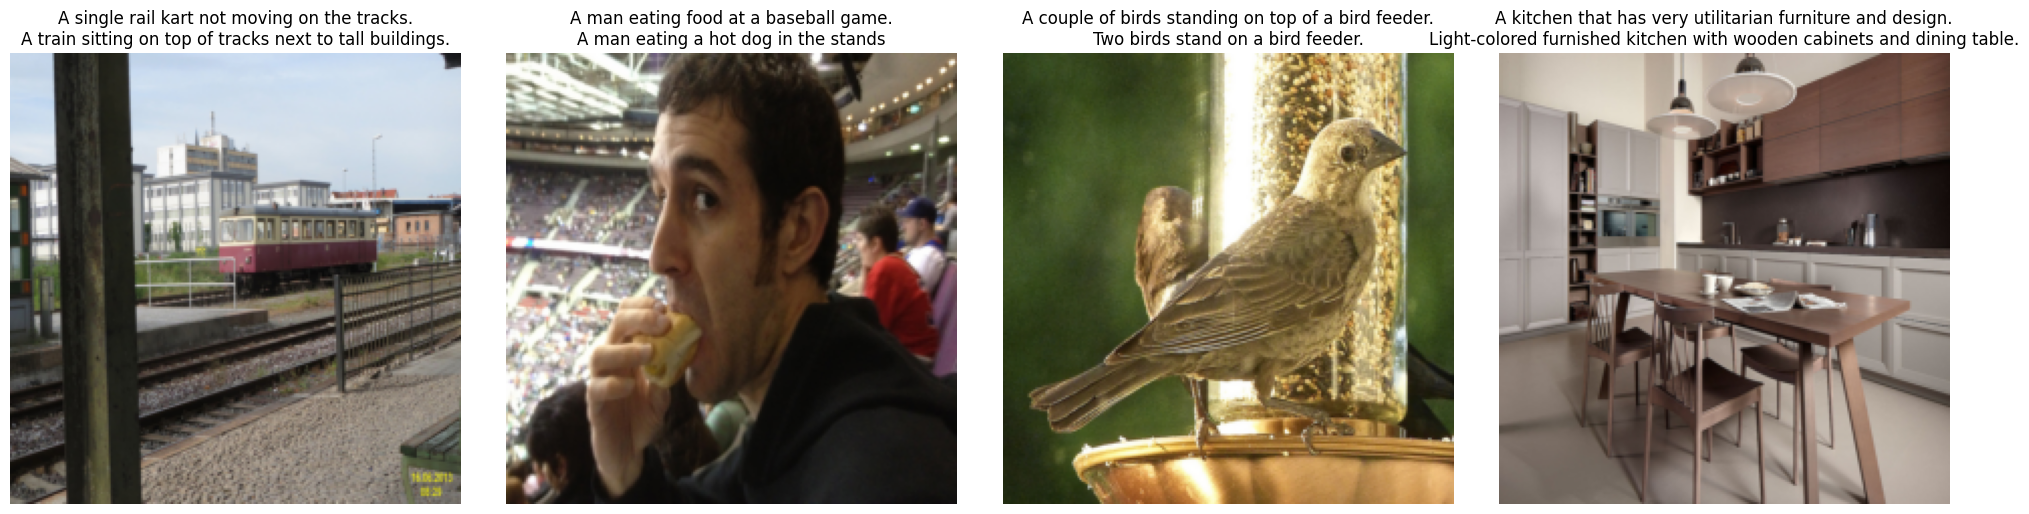

In [45]:
import matplotlib.pyplot as plt
import torch

for images, captions in coco_dataloader:
    print("Images shape:", images.shape)

    n = images.size(0)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        # Undo ImageNet normalization (omit this if your transform doesn't Normalize)
        image = (images[i].cpu() * std + mean).clamp(0, 1)
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.axis("off")
        ax.set_title("\n".join(captions[i][:2]))  # show up to 2 captions

    plt.tight_layout()
    plt.show()
    break